In [5]:
import re
from pathlib import Path

import pandas as pd
from matplotlib import pyplot as plt
import numpy as np

In [2]:
root = Path("./dfs").expanduser()
output_root = Path("./dfs_cleaned")
output_root.mkdir(parents=True, exist_ok=True)


def obs_number(path):
    match = re.search(r"m2_[34]_obs_(\d+)\.csv$", path.name)
    return int(match.group(1)) if match else -1


files = {
    sat: sorted(
        root.rglob(f"{sat}_obs_*.csv"),
        key=obs_number,
    )
    for sat in ("m2_3", "m2_4")
}

data = {sat: {} for sat in files}
seconds = {sat: set() for sat in files}

for sat, paths in files.items():
    for path in paths:
        df = pd.read_csv(path)
        df["_unix_second"] = pd.to_numeric(df["unix_time"], errors="raise").floordiv(1).astype("int64")

        seconds[sat].update(df["_unix_second"].unique())
        data[sat][path] = df

# Seconds observed by both satellites.
overlap_seconds = seconds["m2_3"] & seconds["m2_4"]

print(f"m2_3: {len(seconds['m2_3'])}")
print(f"m2_4: {len(seconds['m2_4'])}")
print(f"overlaps: {len(overlap_seconds)}")  # seconds

# Remove every row in every overlapping second from both satellites.
for _, frames in data.items():
    for path, df in frames.items():
        keep = ~df["_unix_second"].isin(overlap_seconds)
        cleaned = df.loc[keep].drop(columns="_unix_second")

        relative_path = path.relative_to(root)
        output_path = output_root / relative_path
        output_path.parent.mkdir(parents=True, exist_ok=True)

        cleaned.to_csv(output_path, index=False)

        removed = len(df) - len(cleaned)
        if removed:
            print(f"{path.name}: removed {removed:,} rows; kept {len(cleaned):,}")

m2_3: 141019
m2_4: 142056
overlaps: 9747
m2_3_obs_0.csv: removed 1,470 rows; kept 4,079
m2_3_obs_11.csv: removed 4,140 rows; kept 3,330
m2_3_obs_15.csv: removed 4,320 rows; kept 4,710
m2_3_obs_25.csv: removed 1,520 rows; kept 7,660
m2_3_obs_27.csv: removed 430 rows; kept 7,160
m2_3_obs_29.csv: removed 630 rows; kept 3,419
m2_3_obs_37.csv: removed 3,420 rows; kept 5,337
m2_3_obs_49.csv: removed 1,390 rows; kept 6,686
m2_3_obs_60.csv: removed 2,090 rows; kept 1,171
m2_3_obs_62.csv: removed 3,330 rows; kept 5,473
m2_3_obs_63.csv: removed 4,110 rows; kept 758
m2_3_obs_71.csv: removed 3,430 rows; kept 2,114
m2_3_obs_75.csv: removed 3,679 rows; kept 0
m2_3_obs_77.csv: removed 1,960 rows; kept 4,168
m2_3_obs_80.csv: removed 4,300 rows; kept 3,120
m2_3_obs_90.csv: removed 1,050 rows; kept 2,498
m2_3_obs_95.csv: removed 1,530 rows; kept 1,730
m2_3_obs_99.csv: removed 480 rows; kept 8,606
m2_3_obs_102.csv: removed 3,070 rows; kept 1,445
m2_3_obs_112.csv: removed 2,590 rows; kept 6,576
m2_3_obs_1

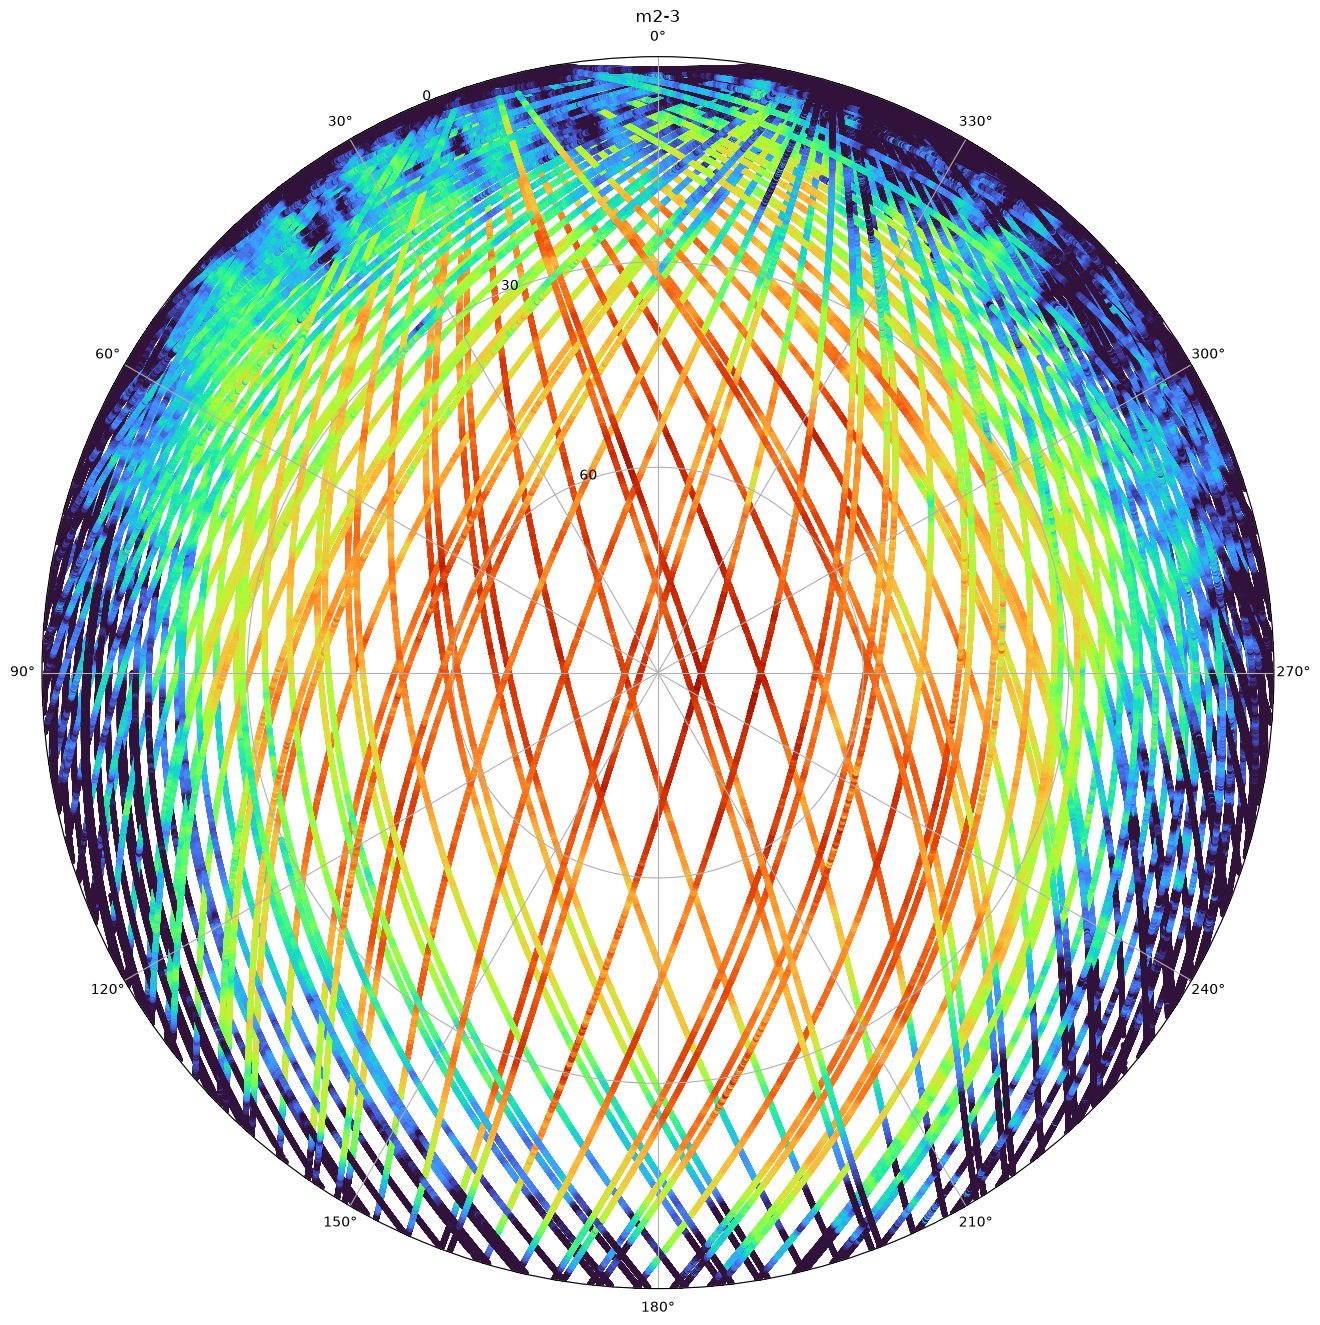

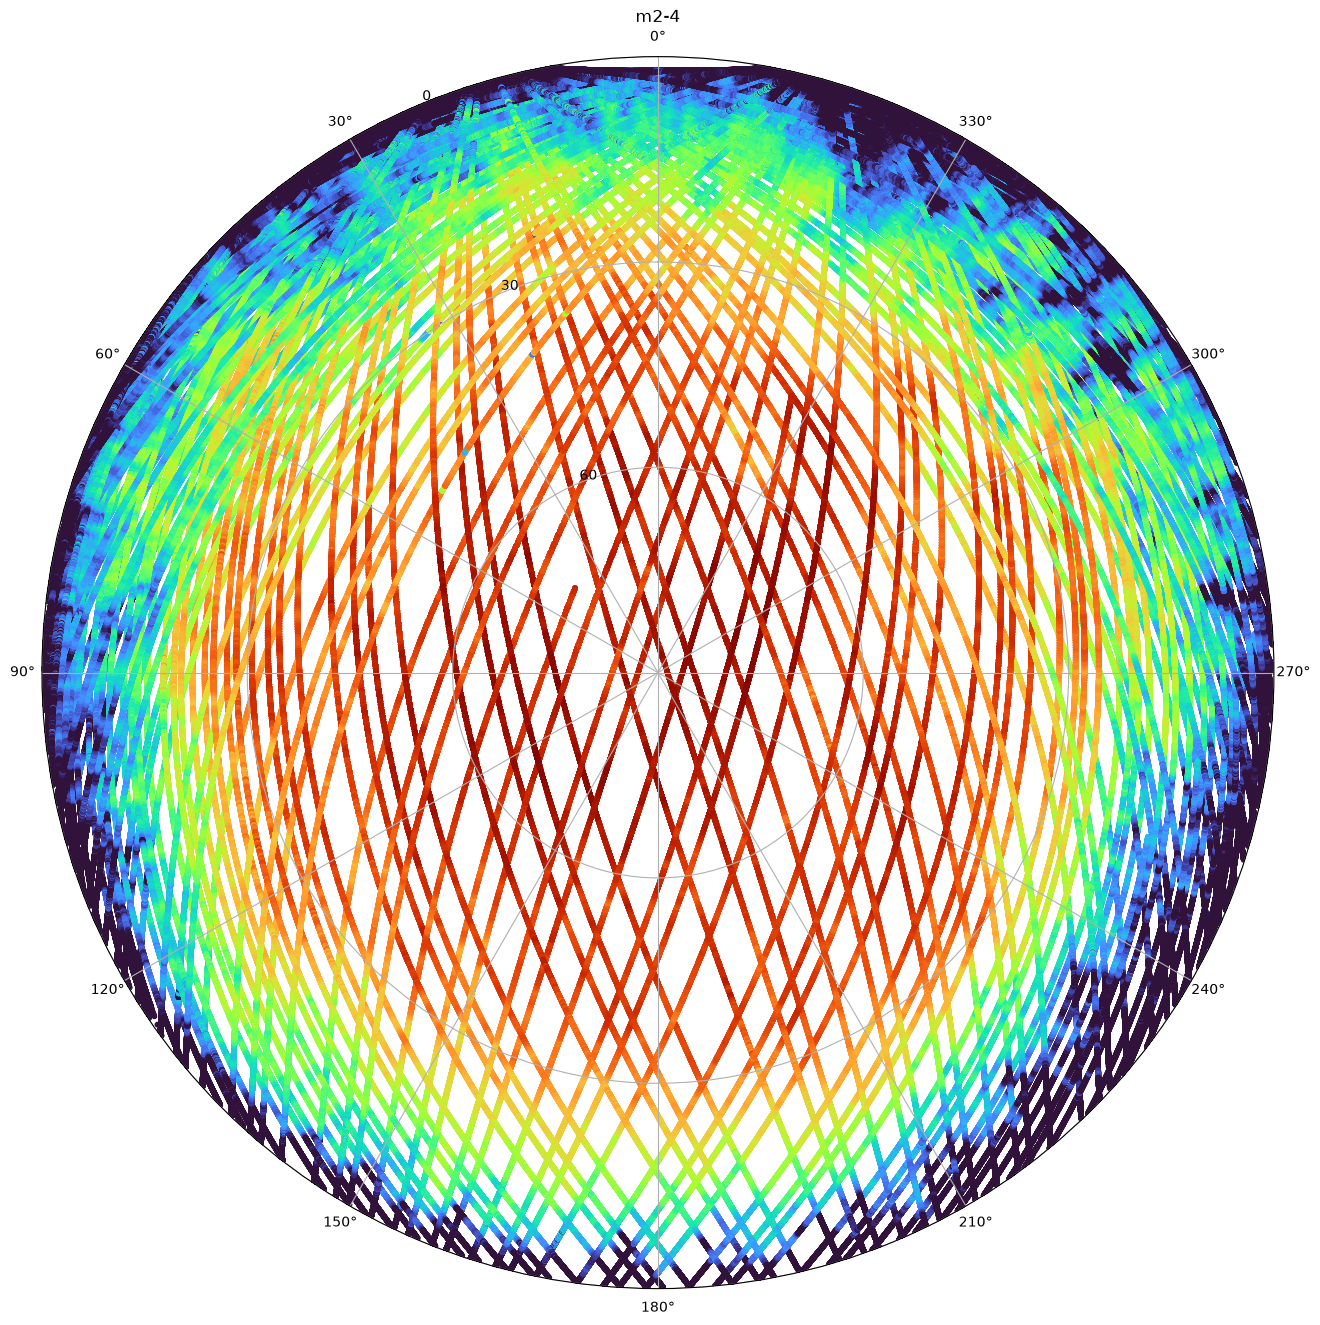

In [7]:

def polar_plot(*dfs, name="", color_range=(-30, 0)):
    fig = plt.figure(figsize=(16, 16))
    ax = plt.subplot(111, polar=True)

    for df in dfs:
        # Convert elevation to radial distance
        alts = 90 - df["alt_deg"].to_numpy()
        azs = np.radians(df["az_deg"].to_numpy())
        power = df["power_db"].to_numpy()

        ax.scatter(
            azs,
            alts,
            c=power,
            cmap="turbo",
            vmin=color_range[0],
            vmax=color_range[1],
            s=10,
        )

    ax.set_theta_zero_location("N")
    ax.set_xlim(0, 2 * np.pi)
    ax.set_ylim(0, 90)

    ax.set_yticks(range(0, 91, 30))
    ax.set_yticklabels(range(90, -1, -30))

    ax.set_xticks(np.radians(range(0, 360, 30)))

    ax.set_title(name)

    return fig

# plot m2-3
dfs = []
for csv_file in sorted(output_root.rglob("m2_3_*.csv")):
    df = pd.read_csv(csv_file)
    dfs.append(df)

polar_plot(*dfs, name="m2-3", color_range=(-30, 0))
plt.show()

# plot m2-4
dfs = []
for csv_file in sorted(output_root.rglob("m2_4_*.csv")):
    df = pd.read_csv(csv_file)
    dfs.append(df)

polar_plot(*dfs, name="m2-4", color_range=(-30, 0))
plt.show()


In [ ]:
# ionospheric effects study:

